In [3]:

# Download historical data for Solana and Cardano

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tokens = {
    "Solana": "SOL-USD",
    "Cardano": "ADA-USD"
}

data = {}

for name, ticker in tokens.items():
    df = yf.download(
        ticker,
        period="5y",
        interval="1d",
        auto_adjust=False,
        progress=False
    )

    if df.empty:
        raise ValueError(f"No data downloaded for {name}.")

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df.loc[:, ~df.columns.duplicated()]
    df.index.name = "Date"
    df = df.sort_index()

    data[name] = df

    print(f"\n{name} data downloaded successfully")
    print(df.head())

print("\nQN1 completed")



Solana data downloaded successfully
Price        Adj Close       Close        High         Low        Open  \
Date                                                                     
2021-10-23  197.703857  197.703857  205.669876  192.562759  196.300476   
2021-10-24  202.361984  202.361984  204.719101  185.572433  197.973114   
2021-10-25  210.104294  210.104294  218.731888  198.202438  202.316483   
2021-10-26  199.807251  199.807251  213.982864  197.486649  209.531647   
2021-10-27  183.774597  183.774597  205.404739  178.730865  199.874481   

Price           Volume  
Date                    
2021-10-23  3253670286  
2021-10-24  3413057378  
2021-10-25  4837376169  
2021-10-26  3194205752  
2021-10-27  4552692842  

Cardano data downloaded successfully
Price       Adj Close     Close      High       Low      Open      Volume
Date                                                                     
2021-10-23   2.166815  2.166815  2.174763  2.134751  2.156006  2115938187
2021-10-2

In [4]:

#Find the number of rows and columns

print("Solana shape:", data["Solana"].shape)
print("Cardano shape:", data["Cardano"].shape)



Solana shape: (1827, 6)
Cardano shape: (1827, 6)


In [5]:

#Display column names

print("Solana columns:")
print(data["Solana"].columns.tolist())

print("\nCardano columns:")
print(data["Cardano"].columns.tolist())


Solana columns:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']

Cardano columns:
['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']


In [6]:

# Display dataset information

print("Solana Information")
data["Solana"].info()

print("\nCardano Information")
data["Cardano"].info()


Solana Information
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1827 entries, 2021-10-23 to 2026-10-23
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  1827 non-null   float64
 1   Close      1827 non-null   float64
 2   High       1827 non-null   float64
 3   Low        1827 non-null   float64
 4   Open       1827 non-null   float64
 5   Volume     1827 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 99.9 KB

Cardano Information
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1827 entries, 2021-10-23 to 2026-10-23
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  1827 non-null   float64
 1   Close      1827 non-null   float64
 2   High       1827 non-null   float64
 3   Low        1827 non-null   float64
 4   Open       1827 non-null   float64
 5   Volume     1827 non-null   int64  
dtypes: float64(5), i

In [7]:

#Check missing values

print("Solana Missing Values")
print(data["Solana"].isnull().sum())

print("\nCardano Missing Values")
print(data["Cardano"].isnull().sum())


Solana Missing Values
Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Cardano Missing Values
Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64


In [8]:
#  Generate statistical summaries

print("Solana Statistics")
print(data["Solana"].describe())

print("\nCardano Statistics")
print(data["Cardano"].describe())


Solana Statistics
Price    Adj Close        Close         High          Low         Open  \
count  1827.000000  1827.000000  1827.000000  1827.000000  1827.000000   
mean    105.258017   105.258017   108.748386   101.782174   105.314131   
std      65.778778    65.778778    67.959216    63.525215    65.819145   
min       9.651783     9.651783     9.827129     8.141268     9.651915   
25%      36.156006    36.156006    37.659744    34.416815    36.193235   
50%     101.669792   101.669792   104.665596    98.580376   101.674622   
75%     153.301743   153.301743   158.479385   147.840935   153.356209   
max     261.869751   261.869751   294.334961   253.187439   261.872437   

Price        Volume  
count  1.827000e+03  
mean   2.976605e+09  
std    2.671649e+09  
min    9.737905e+07  
25%    1.148626e+09  
50%    2.397547e+09  
75%    3.945620e+09  
max    3.317296e+10  

Cardano Statistics
Price    Adj Close        Close         High          Low         Open  \
count  1827.000000  182

In [9]:

#Clean and save the datasets

for name in ["Solana", "Cardano"]:
    data[name] = data[name].replace(
        [np.inf, -np.inf], np.nan
    )

    data[name] = data[name].dropna(subset=["Close"])

    data[name] = data[name].sort_index()

    filename = f"{name}_Cleaned.csv"
    data[name].to_csv(filename)

    print(f"\n{name} cleaned successfully")
    print("Remaining missing values:")
    print(data[name].isnull().sum())
    print("Saved as:", filename)



Solana cleaned successfully
Remaining missing values:
Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64
Saved as: Solana_Cleaned.csv

Cardano cleaned successfully
Remaining missing values:
Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64
Saved as: Cardano_Cleaned.csv


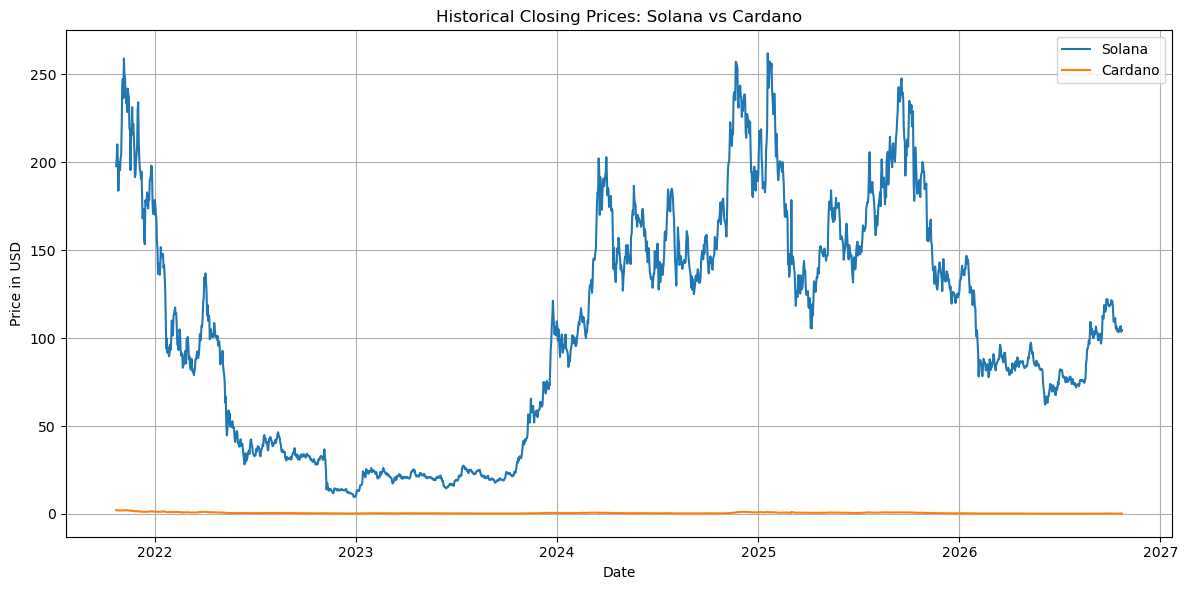

In [10]:

# Plot historical closing prices

plt.figure(figsize=(12, 6))

plt.plot(
    data["Solana"].index,
    data["Solana"]["Close"],
    label="Solana"
)

plt.plot(
    data["Cardano"].index,
    data["Cardano"]["Close"],
    label="Cardano"
)

plt.title("Historical Closing Prices: Solana vs Cardano")
plt.xlabel("Date")
plt.ylabel("Price in USD")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [11]:

# Calculate daily percentage returns

for name in ["Solana", "Cardano"]:
    data[name]["Daily_Return"] = (
        data[name]["Close"].pct_change() * 100
    )

    print(f"\n{name} daily returns:")
    print(data[name][["Close", "Daily_Return"]].head(10))



Solana daily returns:
Price            Close  Daily_Return
Date                                
2021-10-23  197.703857           NaN
2021-10-24  202.361984      2.356113
2021-10-25  210.104294      3.825970
2021-10-26  199.807251     -4.900920
2021-10-27  183.774597     -8.024060
2021-10-28  194.863983      6.034232
2021-10-29  200.182755      2.729479
2021-10-30  195.416061     -2.381171
2021-10-31  202.421021      3.584638
2021-11-01  203.545090      0.555312

Cardano daily returns:
Price          Close  Daily_Return
Date                              
2021-10-23  2.166815           NaN
2021-10-24  2.123435     -2.002018
2021-10-25  2.144066      0.971590
2021-10-26  2.138777     -0.246684
2021-10-27  1.913237    -10.545281
2021-10-28  1.988219      3.919120
2021-10-29  2.012187      1.205500
2021-10-30  1.957422     -2.721665
2021-10-31  1.965026      0.388470
2021-11-01  1.950002     -0.764573


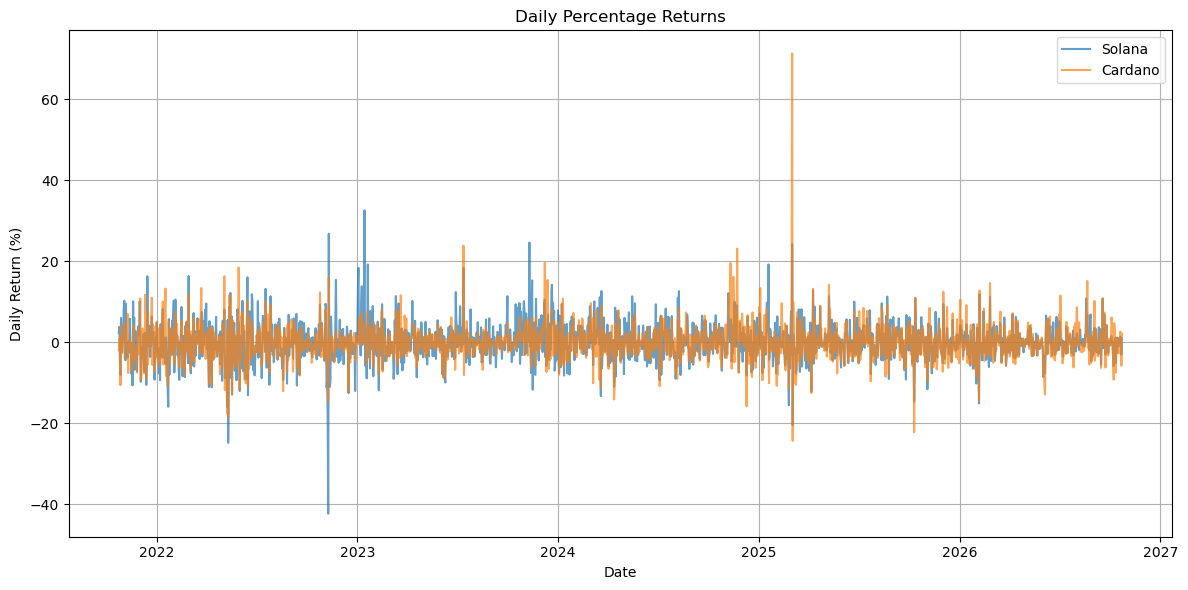

In [12]:

#  Plot daily percentage returns

plt.figure(figsize=(12, 6))

plt.plot(
    data["Solana"].index,
    data["Solana"]["Daily_Return"],
    label="Solana",
    alpha=0.7
)

plt.plot(
    data["Cardano"].index,
    data["Cardano"]["Daily_Return"],
    label="Cardano",
    alpha=0.7
)

plt.title("Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


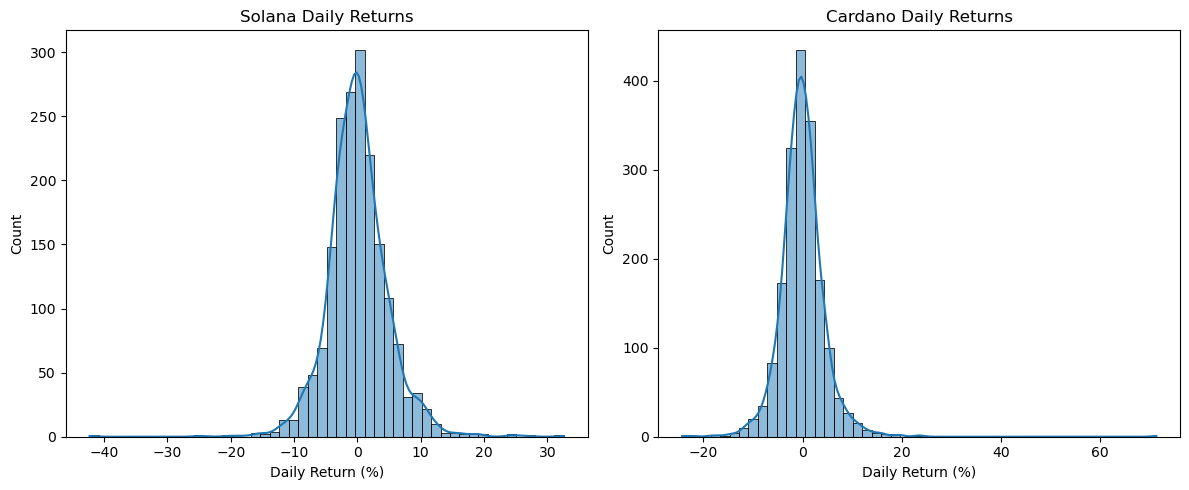

In [13]:

#  Plot daily-return histograms

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data["Solana"]["Daily_Return"].dropna(),
    bins=50,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Solana Daily Returns")
axes[0].set_xlabel("Daily Return (%)")

sns.histplot(
    data["Cardano"]["Daily_Return"].dropna(),
    bins=50,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Cardano Daily Returns")
axes[1].set_xlabel("Daily Return (%)")

plt.tight_layout()
plt.show()



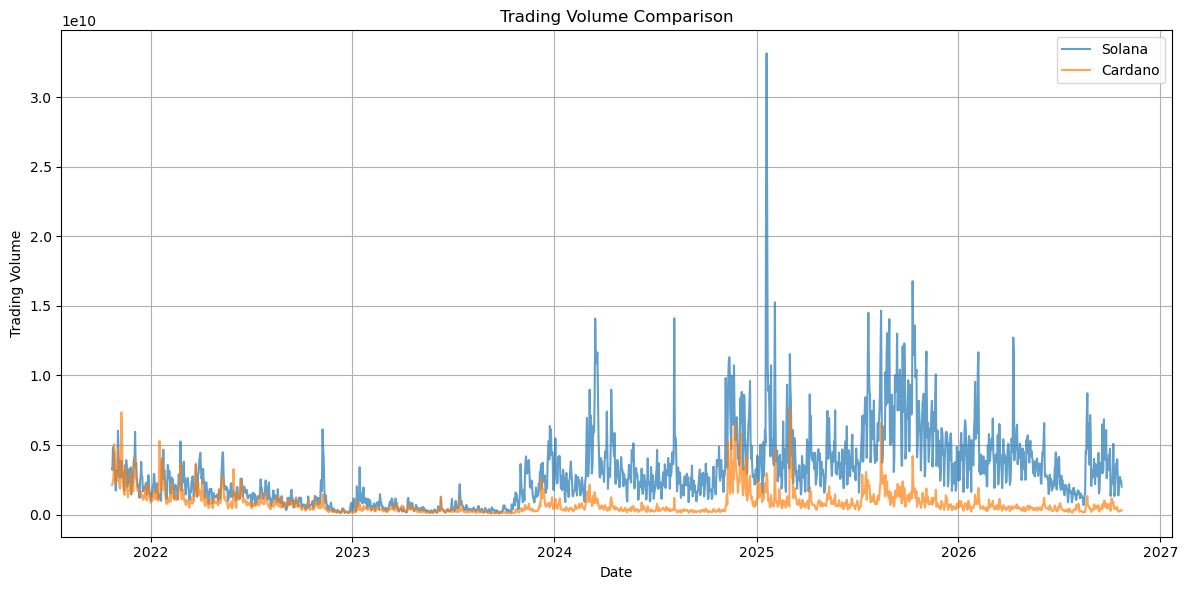

In [14]:

#Compare trading volume

plt.figure(figsize=(12, 6))

plt.plot(
    data["Solana"].index,
    data["Solana"]["Volume"],
    label="Solana",
    alpha=0.7
)

plt.plot(
    data["Cardano"].index,
    data["Cardano"]["Volume"],
    label="Cardano",
    alpha=0.7
)

plt.title("Trading Volume Comparison")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



In [15]:

#Calculate correlation between daily returns

returns = pd.concat(
    [
        data["Solana"]["Daily_Return"].rename("Solana"),
        data["Cardano"]["Daily_Return"].rename("Cardano")
    ],
    axis=1
).dropna()

correlation = returns["Solana"].corr(returns["Cardano"])

print("Correlation between Solana and Cardano daily returns:")
print(correlation)



Correlation between Solana and Cardano daily returns:
0.6997261800692557


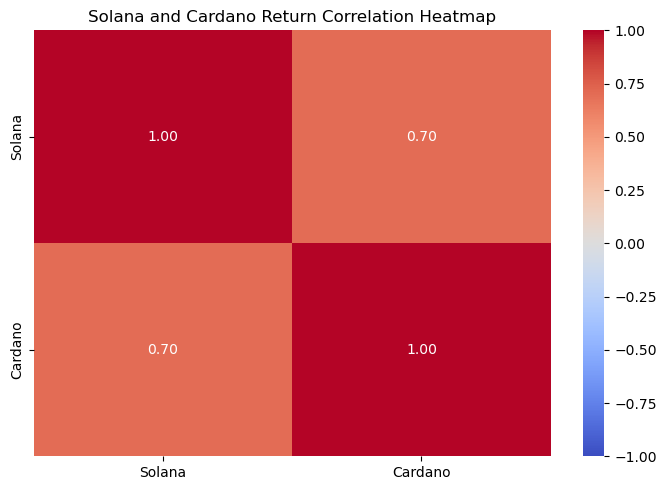

In [16]:

#Create a correlation heatmap

plt.figure(figsize=(7, 5))

sns.heatmap(
    returns.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Solana and Cardano Return Correlation Heatmap")
plt.tight_layout()
plt.show()


In [17]:

# Calculate average daily returns

for name in ["Solana", "Cardano"]:
    average_return = data[name]["Daily_Return"].mean()

    print(f"{name} average daily return: {average_return:.4f}%")



Solana average daily return: 0.0839%
Cardano average daily return: -0.0252%


In [18]:

# Calculate daily-return volatility

for name in ["Solana", "Cardano"]:
    volatility = data[name]["Daily_Return"].std()

    print(f"{name} daily return volatility: {volatility:.4f}%")


Solana daily return volatility: 4.8564%
Cardano daily return volatility: 4.5906%


In [19]:

# Find the highest and lowest closing prices

for name in ["Solana", "Cardano"]:
    df = data[name].dropna(subset=["Close"])

    highest_date = df["Close"].idxmax()
    lowest_date = df["Close"].idxmin()

    print(f"\n{name}")
    print(
        f"Highest closing price: "
        f"${df.loc[highest_date, 'Close']:.4f}"
    )
    print("Highest price date:", highest_date.date())

    print(
        f"Lowest closing price: "
        f"${df.loc[lowest_date, 'Close']:.4f}"
    )
    print("Lowest price date:", lowest_date.date())




Solana
Highest closing price: $261.8698
Highest price date: 2025-01-18
Lowest closing price: $9.6518
Lowest price date: 2022-12-29

Cardano
Highest closing price: $2.2735
Highest price date: 2021-11-09
Lowest closing price: $0.1434
Lowest price date: 2026-06-25


In [20]:

# Find the highest and lowest closing prices

for name in ["Solana", "Cardano"]:
    df = data[name].dropna(subset=["Close"])

    highest_date = df["Close"].idxmax()
    lowest_date = df["Close"].idxmin()

    print(f"\n{name}")
    print(
        f"Highest closing price: "
        f"${df.loc[highest_date, 'Close']:.4f}"
    )
    print("Highest price date:", highest_date.date())

    print(
        f"Lowest closing price: "
        f"${df.loc[lowest_date, 'Close']:.4f}"
    )
    print("Lowest price date:", lowest_date.date())



Solana
Highest closing price: $261.8698
Highest price date: 2025-01-18
Lowest closing price: $9.6518
Lowest price date: 2022-12-29

Cardano
Highest closing price: $2.2735
Highest price date: 2021-11-09
Lowest closing price: $0.1434
Lowest price date: 2026-06-25


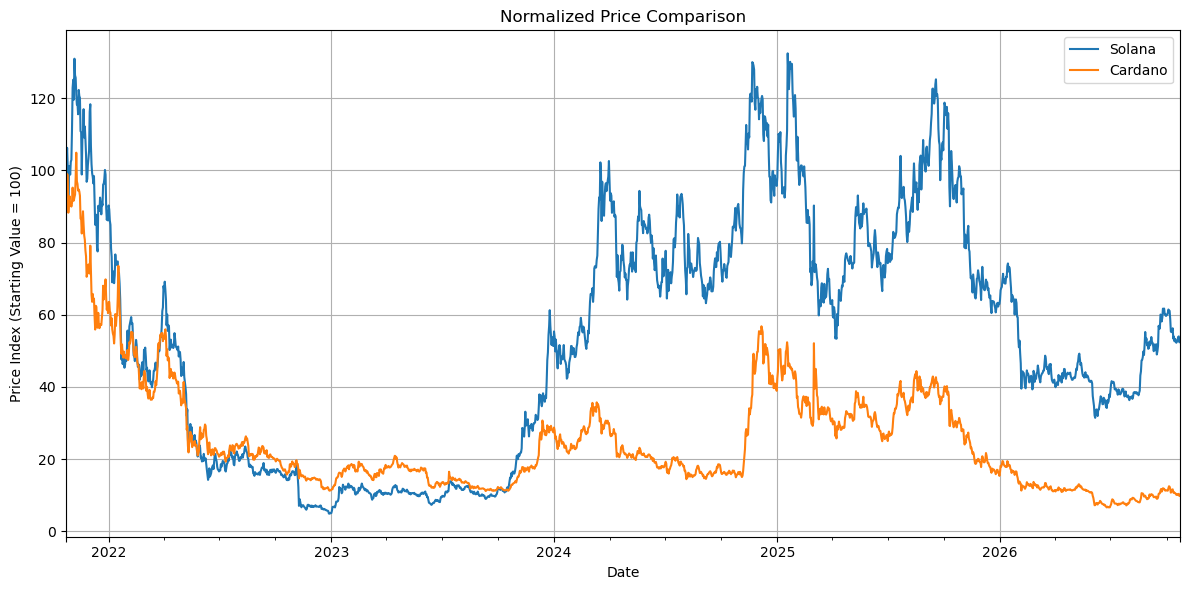

In [21]:

# Compare normalized prices

normalized = pd.DataFrame()

for name in ["Solana", "Cardano"]:
    prices = data[name]["Close"].dropna()

    if prices.empty or prices.iloc[0] == 0:
        raise ValueError(f"Cannot normalize {name} prices.")

    normalized[name] = prices / prices.iloc[0] * 100

normalized.plot(figsize=(12, 6))

plt.title("Normalized Price Comparison")
plt.xlabel("Date")
plt.ylabel("Price Index (Starting Value = 100)")
plt.grid(True)
plt.tight_layout()
plt.show()



In [22]:

#Train Linear Regression models

models = {}
test_data = {}

for name in ["Solana", "Cardano"]:
    df = data[name][["Close"]].dropna().copy()

    df["Previous_Close"] = df["Close"].shift(1)
    df = df.dropna()

    X = df[["Previous_Close"]]
    y = df["Close"]

    split_index = int(len(df) * 0.8)

    X_train = X.iloc[:split_index]
    X_test = X.iloc[split_index:]

    y_train = y.iloc[:split_index]
    y_test = y.iloc[split_index:]

    model = LinearRegression()
    model.fit(X_train, y_train)

    models[name] = model

    test_data[name] = {
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": model.predict(X_test)
    }

    print(f"\n{name} model trained successfully")
    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))



Solana model trained successfully
Training records: 1460
Testing records: 366

Cardano model trained successfully
Training records: 1460
Testing records: 366


In [23]:

#Evaluate model performance

for name in ["Solana", "Cardano"]:
    y_test = test_data[name]["y_test"]
    y_pred = test_data[name]["y_pred"]

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(f"\n{name} Model Evaluation")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}")




Solana Model Evaluation
MAE:  2.5379
RMSE: 3.6525
R²:   0.9839

Cardano Model Evaluation
MAE:  0.0094
RMSE: 0.0128
R²:   0.9873


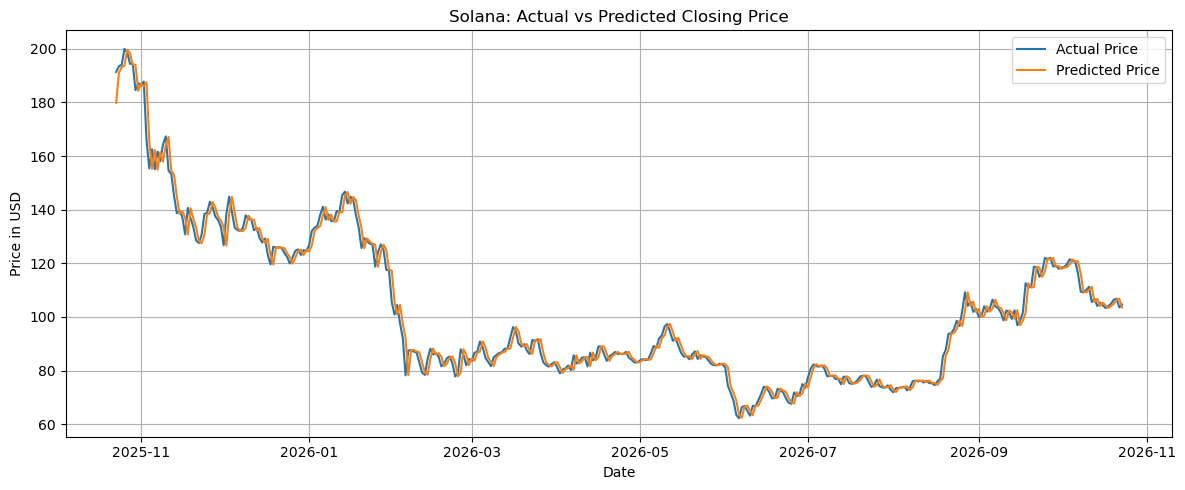

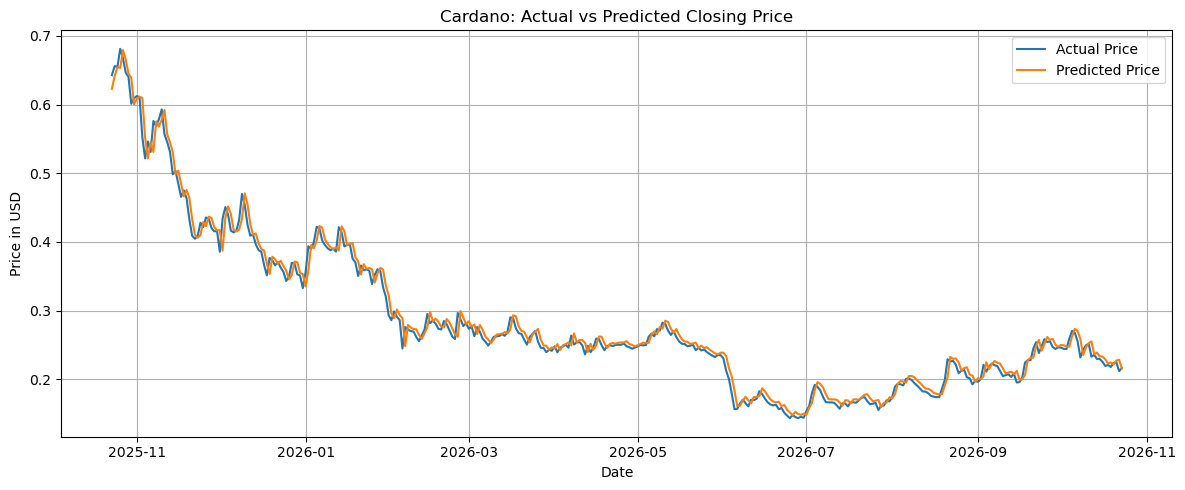

In [24]:

# Plot actual versus predicted prices

for name in ["Solana", "Cardano"]:
    y_test = test_data[name]["y_test"]
    y_pred = test_data[name]["y_pred"]

    plt.figure(figsize=(12, 5))

    plt.plot(
        y_test.index,
        y_test,
        label="Actual Price"
    )

    plt.plot(
        y_test.index,
        y_pred,
        label="Predicted Price"
    )

    plt.title(f"{name}: Actual vs Predicted Closing Price")
    plt.xlabel("Date")
    plt.ylabel("Price in USD")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [25]:

# Estimate the next day's closing price

next_day_predictions = {}

for name in ["Solana", "Cardano"]:
    latest_close = data[name]["Close"].dropna().iloc[-1]

    next_price = models[name].predict(
        pd.DataFrame({"Previous_Close": [latest_close]})
    )[0]

    next_day_predictions[name] = next_price

    print(f"\n{name}")
    print(f"Latest closing price: ${latest_close:.4f}")
    print(f"Estimated next closing price: ${next_price:.4f}")




Solana
Latest closing price: $104.6200
Estimated next closing price: $104.6127

Cardano
Latest closing price: $0.2165
Estimated next closing price: $0.2202


In [26]:

# Save model predictions to CSV

for name in ["Solana", "Cardano"]:
    result = pd.DataFrame({
        "Date": test_data[name]["y_test"].index,
        "Actual_Close": test_data[name]["y_test"].values,
        "Predicted_Close": test_data[name]["y_pred"]
    })

    filename = f"{name}_Predictions.csv"
    result.to_csv(filename, index=False)

    print(f"{name} predictions saved to {filename}")

next_result = pd.DataFrame({
    "Cryptocurrency": list(next_day_predictions.keys()),
    "Estimated_Next_Close_USD": list(next_day_predictions.values())
})

next_result.to_csv("Next_Day_Price_Estimates.csv", index=False)

print("Next-day estimates saved to Next_Day_Price_Estimates.csv")



Solana predictions saved to Solana_Predictions.csv
Cardano predictions saved to Cardano_Predictions.csv
Next-day estimates saved to Next_Day_Price_Estimates.csv


In [27]:

# Final project summary

for name in ["Solana", "Cardano"]:
    df = data[name]
    returns_series = df["Daily_Return"].dropna()

    print(f"\n{name}")
    print("-" * 25)
    print("Total records:", len(df))
    print("First date:", df.index.min().date())
    print("Last date:", df.index.max().date())
    print(f"Average daily return: {returns_series.mean():.4f}%")
    print(f"Daily volatility: {returns_series.std():.4f}%")
    print(f"Highest closing price: ${df['Close'].max():.4f}")
    print(f"Lowest closing price: ${df['Close'].min():.4f}")

    y_test = test_data[name]["y_test"]
    y_pred = test_data[name]["y_pred"]

    print(
        f"Model MAE: "
        f"{mean_absolute_error(y_test, y_pred):.4f}"
    )

print("\nReturn correlation:")
print(returns["Solana"].corr(returns["Cardano"]))

print("\nProject completed successfully.")



Solana
-------------------------
Total records: 1827
First date: 2021-10-23
Last date: 2026-10-23
Average daily return: 0.0839%
Daily volatility: 4.8564%
Highest closing price: $261.8698
Lowest closing price: $9.6518
Model MAE: 2.5379

Cardano
-------------------------
Total records: 1827
First date: 2021-10-23
Last date: 2026-10-23
Average daily return: -0.0252%
Daily volatility: 4.5906%
Highest closing price: $2.2735
Lowest closing price: $0.1434
Model MAE: 0.0094

Return correlation:
0.6997261800692557

Project completed successfully.


**Conclusion**

This project analyzed and compared Solana and Cardano cryptocurrency prices using Python. Data cleaning, statistical analysis, and visualization helped identify price trends, daily returns, and volatility. Linear Regression was used to estimate future closing prices and evaluate prediction accuracy. Overall, this project demonstrates how data analysis and machine learning can help understand cryptocurrency market behavior, although future prices remain uncertain.
